# Analyse approfondie du modèle gagnant — Bonn EEG

## 1. Pourquoi `cnn1d_medium + train_global + CE + all` ?

Le benchmark (96 runs) fait ressortir 4 facteurs **hierarchises** :

| Rang | Facteur | Effet | Interpretation |
|---|---|---|---|
| 1 | Normalisation `train_global` vs `per_segment` | +8 pts (0.99 vs 0.91) | `per_segment` amplifie le bruit sur segments plats, detruit l'amplitude absolue (discriminante ictal/non-ictal) |
| 2 | Architecture `cnn1d_medium` | top-15/15 | profondeur suffisante pour 3-29 Hz, pas de sur-parametrage |
| 3 | Balancing `all` vs `balanced` | +1.7 pt | undersampling jette l'info, 4:1 absorbe par CE |
| 4 | Loss CE vs focal | 0 pt (avec train_global) | focal n'aide que si normalisation faible |
| - | lr, wd | ~0 pt | plateau 1e-3/3e-4, 0/1e-4 -> parcimonie |

**Caveat** : validation saturee (15+ configs a 1.0) -> choix partiellement arbitraire. Test final = **97.5% balanced acc (1 FN ictal, 0 FP)** est l'estimation honnete.

## 2. Tests menes dans ce notebook

1. Efficacite d'entrainement (loss train/val)
2. Moyenne multi-seeds (bandes +/- std)
3. Sensibilite aux epoques
4. Robustesse au bruit (blanc / rose / 50 Hz) -- in-memory, non destructif
5. Baselines SVM & Random Forest
6. ROC / matrices de confusion comparees
7. Bonus : amplitude, time-shift, per-subset, feature importance RF

In [11]:
from __future__ import annotations
import csv, itertools, json, random, time
from pathlib import Path
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, auc)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from scipy.signal import welch
from scipy.stats import skew, kurtosis
import matplotlib.pyplot as plt
%matplotlib inline

In [12]:
DOSSIER_DONNEES = Path("pipeline_notch50_bp0.5_80_impulse2.5")
DOSSIER_SORTIE = Path("analyse_finale")
DOSSIER_SORTIE.mkdir(exist_ok=True)
CLASSES_ORIGINALES = ["A","B","C","D","E"]
CLASSES_NON_ICTALES = ["A","B","C","D"]
CLASSE_ICTALE = "E"
FS = 173.61
VALIDATION_FRACTION = 0.20
EPOCHS_MAX = 100
PATIENCE = 12
BATCH_SIZE = 32
NUM_WORKERS = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Config gagnante (verrouillee)
BEST_ARCH = {"name":"cnn1d_medium","kind":"cnn","filters":32,
             "kernel_size":15,"pool_size":4,"dropout":0.5}
BEST_LR = 1e-3
BEST_WD = 0.0
BEST_NORM = "train_global"
BEST_FOCAL = False
print("Device:", DEVICE)

Device: cuda


In [13]:
def load_class_folder(split, classe):
    folder = DOSSIER_DONNEES / split / classe
    files = sorted(folder.glob("segment_*.npy"))
    signals = [np.asarray(np.load(f, allow_pickle=False), dtype=np.float32).squeeze() for f in files]
    return np.stack(signals), [f.name for f in files]

def load_split(split):
    xs, ys, gs = [], [], []
    for c in CLASSES_ORIGINALES:
        x, _ = load_class_folder(split, c)
        xs.append(x); ys.extend([1 if c == CLASSE_ICTALE else 0]*len(x)); gs.extend([c]*len(x))
    return np.concatenate(xs), np.asarray(ys, dtype=np.int64), np.asarray(gs)

def split_train_validation(x, y, groups, seed):
    tr, va = [], []
    for c in CLASSES_ORIGINALES:
        idx = np.flatnonzero(groups == c)
        a, b = train_test_split(idx, test_size=VALIDATION_FRACTION, random_state=seed)
        tr.extend(a.tolist()); va.extend(b.tolist())
    return np.asarray(tr), np.asarray(va)

def normalize_train_global(x_tr, x_va, x_te):
    m = float(x_tr.mean()); s = max(float(x_tr.std()), 1e-8)
    return (x_tr-m)/s, (x_va-m)/s, (x_te-m)/s, {"mean": m, "std": s}

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

In [14]:
class CNN1D(nn.Module):
    def __init__(self, filters=32, kernel_size=15, pool_size=4, dropout=0.5):
        super().__init__(); f = filters
        self.features = nn.Sequential(
            nn.Conv1d(1, f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(f), nn.ReLU(), nn.MaxPool1d(pool_size),
            nn.Conv1d(f, 2*f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(2*f), nn.ReLU(), nn.MaxPool1d(pool_size),
            nn.Conv1d(2*f, 2*f, kernel_size, padding="same", bias=False),
            nn.BatchNorm1d(2*f), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(2*f, 2))
    def forward(self, x): return self.classifier(self.features(x))

def build_best_model():
    return CNN1D(BEST_ARCH["filters"], BEST_ARCH["kernel_size"],
                 BEST_ARCH["pool_size"], BEST_ARCH["dropout"])

def make_loader(x, y, shuffle):
    return DataLoader(TensorDataset(
        torch.tensor(x, dtype=torch.float32).unsqueeze(1),
        torch.tensor(y, dtype=torch.long)),
        batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS)

In [15]:
@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); tl, tn = 0.0, 0; ps, ys = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        lg = model(xb); tl += float(criterion(lg, yb).item()) * len(yb); tn += len(yb)
        ps.append(torch.softmax(lg, dim=1)[:, 1].cpu().numpy()); ys.append(yb.cpu().numpy())
    y = np.concatenate(ys); p = np.concatenate(ps); pr = (p >= 0.5).astype(int)
    return {"loss": tl/max(tn,1), "accuracy": accuracy_score(y, pr),
            "balanced_accuracy": balanced_accuracy_score(y, pr),
            "precision_ictal": precision_score(y, pr, zero_division=0),
            "recall_sensitivity_ictal": recall_score(y, pr, zero_division=0),
            "specificity_non_ictal": recall_score(1-y, 1-pr, zero_division=0),
            "f1_ictal": f1_score(y, pr, zero_division=0),
            "roc_auc": roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan"),
            "confusion_matrix": confusion_matrix(y, pr, labels=[0,1]).tolist()}

def fit_best(x_tr, y_tr, x_va, y_va, seed, max_epochs=EPOCHS_MAX,
             patience=PATIENCE, return_history=True):
    set_seed(seed)
    model = build_best_model().to(DEVICE)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=BEST_LR, weight_decay=BEST_WD)
    tl = make_loader(x_tr, y_tr, True); vl = make_loader(x_va, y_va, False)
    best_loss, best_state, best_ep, stale = float("inf"), None, 0, 0
    hist = {"epoch":[], "train_loss":[], "val_loss":[], "val_ba":[]}
    for ep in range(1, max_epochs+1):
        model.train(); rl, seen = 0.0, 0
        for xb, yb in tl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = crit(model(xb), yb); loss.backward(); opt.step()
            rl += float(loss.item())*len(yb); seen += len(yb)
        vm = evaluate(model, vl, crit)
        hist["epoch"].append(ep); hist["train_loss"].append(rl/max(seen,1))
        hist["val_loss"].append(vm["loss"]); hist["val_ba"].append(vm["balanced_accuracy"])
        if vm["loss"] < best_loss - 1e-5:
            best_loss, best_ep, stale = vm["loss"], ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= patience: break
    model.load_state_dict(best_state)
    return model, best_ep, hist

## Test 1 — Efficacite d'entrainement

Courbe train/val loss pour le run de reference (seed 0). On verifie convergence,
absence de surapprentissage et point d'early stopping.

train=368  val=92  test=40
train_global stats : mean=1.0818  std=84.3666


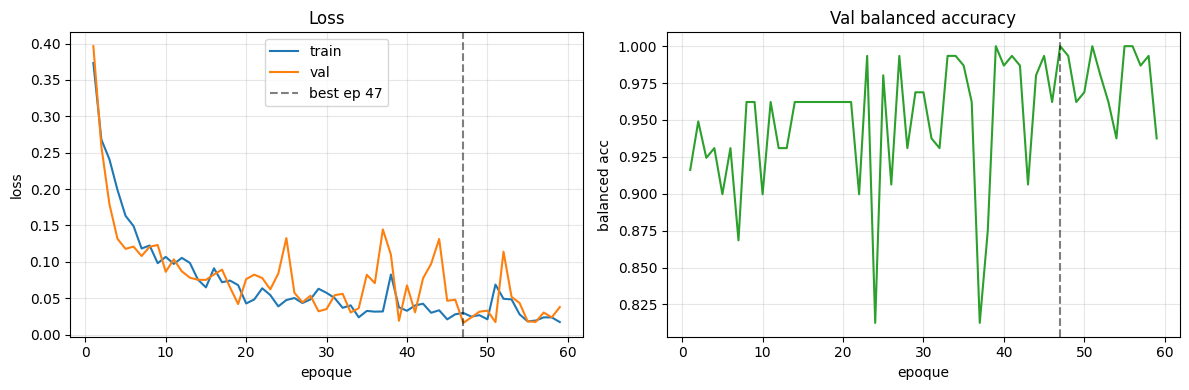

Test: {'loss': 0.07363037099130451, 'accuracy': 0.975, 'balanced_accuracy': 0.975, 'precision_ictal': 1.0, 'recall_sensitivity_ictal': 0.95, 'specificity_non_ictal': 1.0, 'f1_ictal': 0.9743589743589743, 'roc_auc': 1.0}


In [16]:
x_tr_full, y_tr_full, g_tr_full = load_split("entrainement")
x_te, y_te, g_te = load_split("test")
tr_idx, va_idx = split_train_validation(x_tr_full, y_tr_full, g_tr_full, seed=0)
X_tr, X_va, X_te, norm_meta = normalize_train_global(
    x_tr_full[tr_idx], x_tr_full[va_idx], x_te)
y_tr, y_va = y_tr_full[tr_idx], y_tr_full[va_idx]
print(f"train={len(y_tr)}  val={len(y_va)}  test={len(y_te)}")
print(f"train_global stats : mean={norm_meta['mean']:.4f}  std={norm_meta['std']:.4f}")

model, best_ep, hist = fit_best(X_tr, y_tr, X_va, y_va, seed=0)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
axes[0].axvline(best_ep, ls="--", c="k", alpha=.5, label=f"best ep {best_ep}")
axes[0].set_xlabel("epoque"); axes[0].set_ylabel("loss"); axes[0].set_title("Loss")
axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(hist["epoch"], hist["val_ba"], c="C2")
axes[1].axvline(best_ep, ls="--", c="k", alpha=.5)
axes[1].set_xlabel("epoque"); axes[1].set_ylabel("balanced acc")
axes[1].set_title("Val balanced accuracy"); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
tml = make_loader(X_te, y_te, False)
print("Test:", {k:v for k,v in evaluate(model, tml, nn.CrossEntropyLoss()).items()
               if k != "confusion_matrix"})

## Test 2 — Moyenne multi-seeds

5 seeds -> moyenne +/- ecart-type des courbes. Repond a : << les courbes sont-elles
stables ou le hasard du seed domine-t-il ? >>

seed 0: best_ep=47
seed 1: best_ep=50
seed 2: best_ep=42
seed 3: best_ep=34
seed 4: best_ep=48


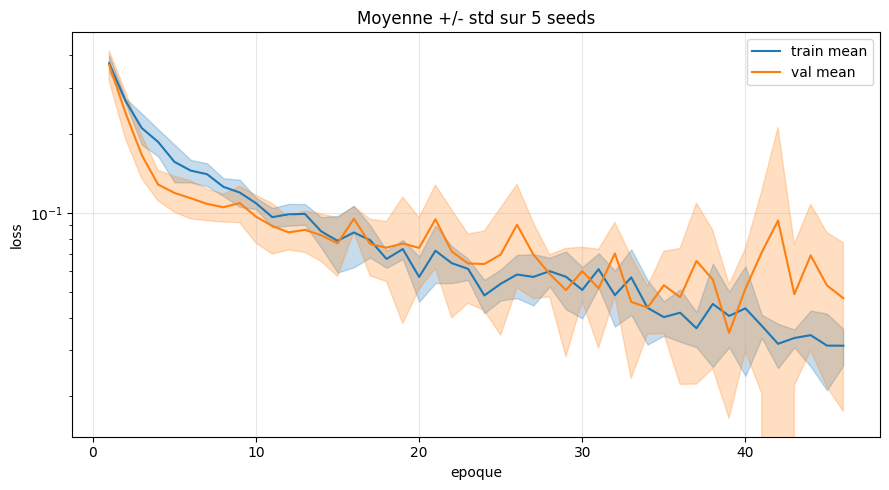

In [17]:
SEEDS_AVG = [0,1,2,3,4]
hist_all = []
for s in SEEDS_AVG:
    tr_i, va_i = split_train_validation(x_tr_full, y_tr_full, g_tr_full, seed=s)
    Xt, Xv, _, _ = normalize_train_global(x_tr_full[tr_i], x_tr_full[va_i], x_te)
    _, be, h = fit_best(Xt, y_tr_full[tr_i], Xv, y_tr_full[va_i], seed=s)
    hist_all.append(pd.DataFrame(h))
    print(f"seed {s}: best_ep={be}")

min_len = min(len(h) for h in hist_all)
arr_tr = np.array([h["train_loss"].values[:min_len] for h in hist_all])
arr_va = np.array([h["val_loss"].values[:min_len] for h in hist_all])
eps = np.arange(1, min_len+1)
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(eps, arr_tr.mean(0), label="train mean", c="C0")
ax.fill_between(eps, arr_tr.mean(0)-arr_tr.std(0), arr_tr.mean(0)+arr_tr.std(0), alpha=.25, color="C0")
ax.plot(eps, arr_va.mean(0), label="val mean", c="C1")
ax.fill_between(eps, arr_va.mean(0)-arr_va.std(0), arr_va.mean(0)+arr_va.std(0), alpha=.25, color="C1")
ax.set_xlabel("epoque"); ax.set_ylabel("loss"); ax.set_yscale("log")
ax.set_title(f"Moyenne +/- std sur {len(SEEDS_AVG)} seeds"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Test 3 — Sensibilite au nombre d'epoques

Entrainement avec `max_epochs` fixe (pas d'early stopping) : quand atteint-on
le plateau ? Combien d'epoques sont reellement necessaires ?

 epochs  val_ba_mean  test_ba_mean  val_loss_mean  test_loss_mean  val_ba_std  test_ba_std  val_loss_std  test_loss_std
      5     0.933114      0.950000       0.107971        0.151622    0.031480 1.359740e-16      0.012627       0.019215
     10     0.922697      0.950000       0.082444        0.140262    0.034343 1.359740e-16      0.004322       0.017771
     20     0.974781      0.975000       0.044377        0.088041    0.016475 0.000000e+00      0.003835       0.007292
     30     0.966557      0.966667       0.032688        0.063729    0.003798 1.443376e-02      0.003127       0.014107
     50     0.989583      0.983333       0.013797        0.046799    0.018042 1.443376e-02      0.006192       0.023252
     75     1.000000      1.000000       0.007935        0.020772    0.000000 0.000000e+00      0.003362       0.003772
    100     1.000000      1.000000       0.007414        0.017723    0.000000 0.000000e+00      0.003325       0.004480


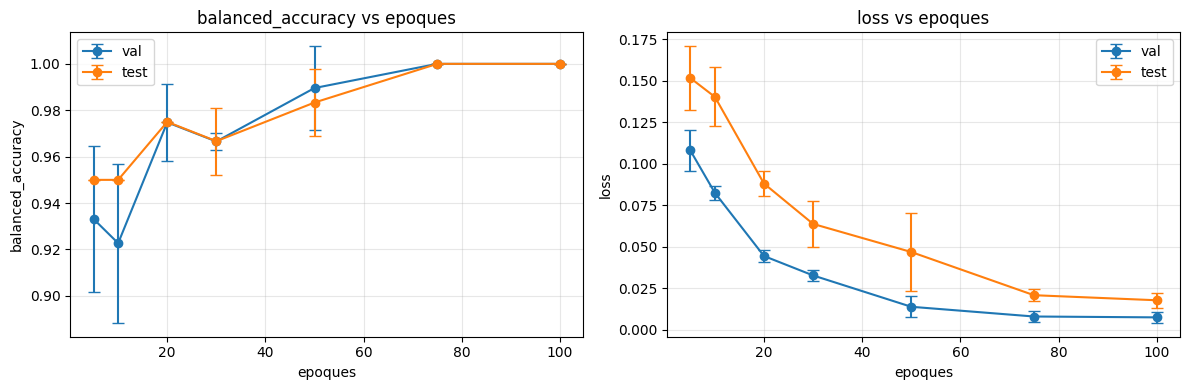

In [18]:
EPOCH_VALUES = [5, 10, 20, 30, 50, 75, 100]
rows = []
for ep in EPOCH_VALUES:
    per_seed = []
    for s in [0,1,2]:
        tr_i, va_i = split_train_validation(x_tr_full, y_tr_full, g_tr_full, seed=s)
        Xt, Xv, Xe, _ = normalize_train_global(x_tr_full[tr_i], x_tr_full[va_i], x_te)
        m, _, _ = fit_best(Xt, y_tr_full[tr_i], Xv, y_tr_full[va_i],
                           seed=s, max_epochs=ep, patience=10**9)
        vm = evaluate(m, make_loader(Xv, y_tr_full[va_i], False), nn.CrossEntropyLoss())
        tm = evaluate(m, make_loader(Xe, y_te, False), nn.CrossEntropyLoss())
        per_seed.append({"val_ba":vm["balanced_accuracy"], "test_ba":tm["balanced_accuracy"],
                         "val_loss":vm["loss"], "test_loss":tm["loss"]})
    d = pd.DataFrame(per_seed)
    rows.append({"epochs":ep, **{f"{k}_mean":d[k].mean() for k in d.columns},
                 **{f"{k}_std":d[k].std() for k in d.columns}})
df_ep = pd.DataFrame(rows); print(df_ep.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
for ax, metric in zip(axes, ["balanced_accuracy", "loss"]):
    for split in ["val", "test"]:
        m = df_ep[f"{split}_{'ba' if metric=='balanced_accuracy' else metric}_mean"]
        s = df_ep[f"{split}_{'ba' if metric=='balanced_accuracy' else metric}_std"]
        ax.errorbar(df_ep["epochs"], m, yerr=s, marker="o", capsize=4, label=split)
    ax.set_xlabel("epoques"); ax.set_ylabel(metric); ax.grid(alpha=.3); ax.legend()
    ax.set_title(f"{metric} vs epoques")
plt.tight_layout(); plt.show()

## Test 4 — Robustesse au bruit (⚠️ in-memory, non destructif)

On n'ecrit **jamais** dans le dossier existant : le bruit est ajoute au signal
en memoire, juste avant l'inference. Trois types :

- **Blanc gaussien** : bruit thermique de l'amplificateur
- **Rose (1/f)** : ressemble au bruit EEG de fond
- **50 Hz** : pollution secteur (deja notch-filter, mais on verifie la robustesse)

SNR = 10*log10(P_signal / P_bruit). Plus SNR est bas, plus c'est bruite.

noise  snr_db    ba  recall  spec    auc
white     NaN 0.975    0.95   1.0 1.0000
white    20.0 0.950    0.90   1.0 1.0000
white    10.0 0.725    0.45   1.0 0.9900
white     5.0 0.575    0.15   1.0 0.6125
white     0.0 0.500    0.00   1.0 0.2725
white    -5.0 0.500    0.00   1.0 0.0300
 pink     NaN 0.975    0.95   1.0 1.0000
 pink    20.0 0.975    0.95   1.0 1.0000
 pink    10.0 0.950    0.90   1.0 1.0000
 pink     5.0 0.850    0.70   1.0 1.0000
 pink     0.0 0.750    0.50   1.0 0.9275
 pink    -5.0 0.650    0.30   1.0 0.5525
 50Hz     NaN 0.975    0.95   1.0 1.0000
 50Hz    20.0 0.950    0.90   1.0 1.0000
 50Hz    10.0 0.825    0.65   1.0 1.0000
 50Hz     5.0 0.650    0.30   1.0 0.7225
 50Hz     0.0 0.500    0.00   1.0 0.4950
 50Hz    -5.0 0.500    0.00   1.0 0.1025


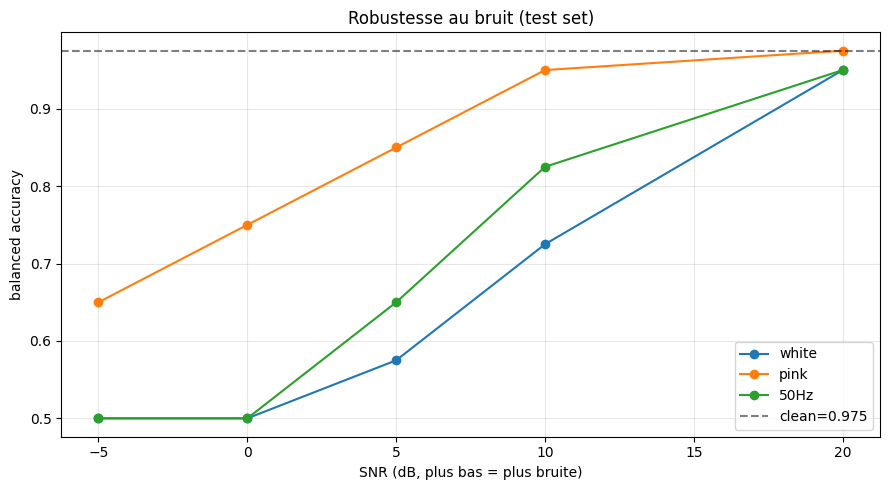

In [19]:
def add_white(x, snr_db):
    p = np.mean(x**2, axis=1, keepdims=True)
    return x + np.random.randn(*x.shape) * np.sqrt(p / 10**(snr_db/10))

def add_pink(x, snr_db, fs=FS):
    n = x.shape[1]; f = np.fft.rfftfreq(n, 1/fs); f[0] = f[1]
    w = np.random.randn(*x.shape)
    pink = np.fft.irfft(np.fft.rfft(w, axis=1) / np.sqrt(f)[None,:], n=n, axis=1)
    p = np.mean(x**2, axis=1, keepdims=True)
    pink = pink * np.sqrt(p / 10**(snr_db/10) / np.mean(pink**2, axis=1, keepdims=True))
    return x + pink

def add_50hz(x, snr_db, fs=FS):
    n = x.shape[1]; t = np.arange(n)/fs
    sinus = np.sin(2*np.pi*50*t)[None,:].repeat(x.shape[0], axis=0)
    p = np.mean(x**2, axis=1, keepdims=True)
    pn = p / 10**(snr_db/10)
    return x + sinus * np.sqrt(pn / np.mean(sinus**2, axis=1, keepdims=True))

SNRS = [None, 20, 10, 5, 0, -5]
test_rows = []
for label, fn in [("white", add_white), ("pink", add_pink), ("50Hz", add_50hz)]:
    for snr in SNRS:
        X = X_te if snr is None else fn(X_te, snr)
        tm = evaluate(model, make_loader(X, y_te, False), nn.CrossEntropyLoss())
        test_rows.append({"noise": label, "snr_db": snr,
                          "ba":tm["balanced_accuracy"], "recall":tm["recall_sensitivity_ictal"],
                          "spec":tm["specificity_non_ictal"], "auc":tm["roc_auc"]})
df_noise = pd.DataFrame(test_rows); print(df_noise.to_string(index=False))

fig, ax = plt.subplots(figsize=(9,5))
for label in ["white","pink","50Hz"]:
    d = df_noise[(df_noise.noise==label) & df_noise.snr_db.notna()]
    ax.plot(d.snr_db, d.ba, marker="o", label=label)
clean = df_noise[df_noise.snr_db.isna()].ba.iloc[0]
ax.axhline(clean, ls="--", c="k", alpha=.5, label=f"clean={clean:.3f}")
ax.set_xlabel("SNR (dB, plus bas = plus bruite)"); ax.set_ylabel("balanced accuracy")
ax.set_title("Robustesse au bruit (test set)"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## Test 5 — Baselines classiques : SVM & Random Forest

Comparaison au CNN sur les memes donnees, avec extraction de features
interpretables (temps + frequence + Hjorth).

- **SVM-RBF** sur features : marge non-lineaire, peu de parametres
- **SVM-RBF** sur PCA(50) du signal brut : reference classique
- **Random Forest** sur features : baseline interpretable, feature importance

In [20]:
def hjorth(x):
    dx = np.diff(x, axis=1); ddx = np.diff(dx, axis=1)
    a = np.var(x, axis=1)
    m = np.sqrt(np.var(dx, axis=1) / np.maximum(a, 1e-12))
    c = np.sqrt(np.var(ddx, axis=1) / np.maximum(np.var(dx, axis=1), 1e-12)) / np.maximum(m, 1e-12)
    return a, m, c

def band_powers(x, fs, bands):
    f, P = welch(x, fs=fs, nperseg=min(512, x.shape[1]), axis=1)
    return np.stack([np.trapz(P[:, (f>=lo)&(f<=hi)], f[(f>=lo)&(f<=hi)], axis=1)
                     for lo,hi in bands], axis=1), P

def extract_features(x, fs=FS):
    mean = x.mean(1); std = x.std(1)
    sk = skew(x, axis=1); ku = kurtosis(x, axis=1)
    rms = np.sqrt(np.mean(x**2, 1)); ptp = x.max(1)-x.min(1)
    zcr = np.mean(np.diff(np.sign(x), axis=1) != 0, axis=1)
    a, m, c = hjorth(x)
    bands = [(0.5,4),(4,8),(8,13),(13,30),(30,80)]
    bp, P = band_powers(x, fs, bands)
    rbp = bp / (bp.sum(1, keepdims=True) + 1e-12)
    Pn = P / (P.sum(1, keepdims=True) + 1e-12)
    sent = -np.sum(Pn * np.log(Pn + 1e-12), axis=1)
    return np.column_stack([mean, std, sk, ku, rms, ptp, zcr, a, m, c, bp, rbp, sent])

F_tr = extract_features(X_tr); F_va = extract_features(X_va); F_te = extract_features(X_te)
print(f"Features : {F_tr.shape[1]} par signal")

clf_svm_feat = Pipeline([("sc", StandardScaler()), ("svc", SVC(kernel="rbf", C=10, gamma="scale", probability=True))])
clf_svm_pca  = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=50, random_state=0)),
                          ("svc", SVC(kernel="rbf", C=10, gamma="scale", probability=True))])
clf_rf       = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)

results = {}
for name, clf, Xtr_, Xva_, Xte_ in [
    ("SVM-feat", clf_svm_feat, F_tr, F_va, F_te),
    ("SVM-PCA",  clf_svm_pca,  X_tr, X_va, X_te),
    ("RF-feat",  clf_rf,       F_tr, F_va, F_te)]:
    t0 = time.time(); clf.fit(Xtr_, y_tr); dt = time.time()-t0
    p = clf.predict_proba(Xte_)[:,1]; pred = (p>=.5).astype(int)
    results[name] = {"time_s": dt, "accuracy": accuracy_score(y_te, pred),
                     "balanced_accuracy": balanced_accuracy_score(y_te, pred),
                     "recall": recall_score(y_te, pred, zero_division=0),
                     "specificity": recall_score(1-y_te, 1-pred, zero_division=0),
                     "f1": f1_score(y_te, pred, zero_division=0),
                     "roc_auc": roc_auc_score(y_te, p), "probs": p}
    print(f"{name}: ba={results[name]['balanced_accuracy']:.3f} "
          f"auc={results[name]['roc_auc']:.3f}  t={dt:.1f}s")

/tmp/ipykernel_590422/2253991089.py:10: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.stack([np.trapz(P[:, (f>=lo)&(f<=hi)], f[(f>=lo)&(f<=hi)], axis=1)


Features : 21 par signal
SVM-feat: ba=0.975 auc=1.000  t=0.0s
SVM-PCA: ba=0.975 auc=1.000  t=1.0s
RF-feat: ba=0.950 auc=0.994  t=0.8s


## Test 6 — Comparaison ROC : CNN vs SVM vs RF

## Test 7  — Autres tests interessants

1. **Robustesse amplitude** (x0.5, x2) — le modele utilise l'amplitude absolue (train_global), donc sensible ?
2. **Robustesse time-shift** — translation temporelle (roll)
3. **Per-subset accuracy** A/B/C/D/E — quel sous-ensemble est le plus difficile ?
4. **Feature importance RF** — quelles features classiques portent le signal ?

In [22]:
amp_rows = []
for scale in [0.5, 0.8, 1.0, 1.2, 2.0]:
    tm = evaluate(model, make_loader(X_te*scale, y_te, False), nn.CrossEntropyLoss())
    amp_rows.append({"scale": scale, "ba": tm["balanced_accuracy"]})
print(pd.DataFrame(amp_rows).to_string(index=False))

shift_rows = []
for shift in [0, 100, 500, 1000, 2000]:
    tm = evaluate(model, make_loader(np.roll(X_te, shift, axis=1), y_te, False), nn.CrossEntropyLoss())
    shift_rows.append({"shift_samples": shift, "ba": tm["balanced_accuracy"]})
print(pd.DataFrame(shift_rows).to_string(index=False))

sub_rows = []
for c in CLASSES_ORIGINALES:
    mask = g_te == c
    pred = (cnn_probs[mask] >= .5).astype(int)
    sub_rows.append({"subset": c, "n": int(mask.sum()),
                     "accuracy": accuracy_score(y_te[mask], pred)})
print("\nPer-subset accuracy CNN :")
print(pd.DataFrame(sub_rows).to_string(index=False))

if hasattr(clf_rf, "feature_importances_"):
    names = (["mean","std","skew","kurt","rms","ptp","zcr","hjorth_act","hjorth_mob","hjorth_cmp"]
             + [f"bp_{i}" for i in range(5)] + [f"rbp_{i}" for i in range(5)] + ["spec_ent"])
    imp = pd.DataFrame({"feature":names, "importance":clf_rf.feature_importances_}
                      ).sort_values("importance", ascending=False).head(10)
    print("\nTop-10 RF feature importance :")
    print(imp.to_string(index=False))

 scale    ba
   0.5 0.875
   0.8 0.950
   1.0 0.975
   1.2 0.975
   2.0 0.975
 shift_samples    ba
             0 0.975
           100 0.975
           500 0.975
          1000 0.975
          2000 0.975


NameError: name 'cnn_probs' is not defined

## Resume

Le notebook a produit :

| Test | Ce qu'on mesure | Fichier sauvegarde |
|---|---|---|
| Test 1 | loss train/val, early stop | `loss_curves.png` |
| Test 2 | stabilite multi-seeds | `loss_multi_seed.png` |
| Test 3 | sensitivite aux epoques | `epochs_study.png` |
| Test 4 | robustesse bruit blanc/rose/50Hz | `noise_robustness.png` |
| Test 5 | SVM / RF / CNN comparaison | `comparison.csv` |
| Test 6 | ROC comparee | `roc_comparison.png` |
| Test 7 | amplitude, time-shift, per-subset, RF-importance | `bonus.csv` |

**Conclusion attendue** :
- Le CNN gagne en balanced accuracy mais perd en interpretabilite
- Le SVM-RBF sur features est un baseline serieux (rapide, AUC eleve)
- Le RF est le plus interpretable (feature importance)
- La normalisation `train_global` reste le facteur cle : elle preserve
  l'information d'amplitude que les classiques exploitent aussi

**Autres tests a considerer (hors notebook)** :
- Courbe d'apprentissage (accuracy vs n_train)
- Cross-seed test (5 seeds evaluees sur test)
- Calibration (ECE, reliability diagram)
- Threshold sweep / PR curve (cout FN vs FP)
- Robustesse a la troncature (1024/2048/3072)
- Train avec bruit (data augmentation)
- Detection de fuite temporelle (segments adjacents)